# Online Gaming Behavior 

# Introduction

**Player engagement is a key factor in the success of online games.The objective of this project is to predict whether a player's engagement level is Low,Medium or High based on their demographics,gameplay behavior and in-game activities.**

# 1.Import Library

In [45]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OrdinalEncoder,OneHotEncoder
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,classification_report,ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

# 2.Data Overview

## 2.1 Load dataset

In [46]:
df = pd.read_csv("online_gaming_behavior_dataset.csv")

## 2.2 First five rows

In [47]:
df.head()

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


## 2.3 Column description

| Column Name | Description |
|-------------|-------------|
| **PlayerID** | Unique identifier assigned to each player. |
| **Age** | Age of the player in years. |
| **Gender** | Gender of the player (e.g., Male, Female, Other). |
| **Location** | Geographic location or region of the player. |
| **GameGenre** | Preferred genre of the game played. |
| **PlayTimeHours** | Total number of hours spent playing the game. |
| **InGamePurchases** | Indicates whether the player has made in-game purchases. |
| **GameDifficulty** | Difficulty level selected by the player (e.g., Easy, Medium, Hard). |
| **SessionsPerWeek** | Number of gaming sessions played per week. |
| **AvgSessionDurationMinutes** | Average duration of each gaming session in minutes. |
| **PlayerLevel** | Current level achieved by the player in the game. |
| **AchievementsUnlocked** | Total number of achievements unlocked by the player. |
| **EngagementLevel** | Target variable representing the player's engagement level (e.g., Low, Medium, High). |

## 2.4 Shape of data

In [4]:
df.shape

(40034, 13)

## 2.5 Datatype of each column

In [5]:
df.dtypes

PlayerID                       int64
Age                            int64
Gender                        object
Location                      object
GameGenre                     object
PlayTimeHours                float64
InGamePurchases                int64
GameDifficulty                object
SessionsPerWeek                int64
AvgSessionDurationMinutes      int64
PlayerLevel                    int64
AchievementsUnlocked           int64
EngagementLevel               object
dtype: object

## 2.6 Information of each column

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int64  
 1   Age                        40034 non-null  int64  
 2   Gender                     40034 non-null  object 
 3   Location                   40034 non-null  object 
 4   GameGenre                  40034 non-null  object 
 5   PlayTimeHours              40034 non-null  float64
 6   InGamePurchases            40034 non-null  int64  
 7   GameDifficulty             40034 non-null  object 
 8   SessionsPerWeek            40034 non-null  int64  
 9   AvgSessionDurationMinutes  40034 non-null  int64  
 10  PlayerLevel                40034 non-null  int64  
 11  AchievementsUnlocked       40034 non-null  int64  
 12  EngagementLevel            40034 non-null  object 
dtypes: float64(1), int64(7), object(5)
memory usag

In [7]:
df.describe()

,PlayerID,Age,PlayTimeHours,InGamePurchases,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
count,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000
mean,29016.500000,31.992531,12.024365,0.200854,9.471774,94.792252,49.655568,24.526477
std,11556.964675,10.043227,6.914638,0.400644,5.763667,49.011375,28.588379,14.430726
min,9000.000000,15.000000,0.000115,0.000000,0.000000,10.000000,1.000000,0.000000
25%,19008.250000,23.000000,6.067501,0.000000,4.000000,52.000000,25.000000,12.000000
50%,29016.500000,32.000000,12.008002,0.000000,9.000000,95.000000,49.000000,25.000000
75%,39024.750000,41.000000,17.963831,0.000000,14.000000,137.000000,74.000000,37.000000
max,49033.000000,49.000000,23.999592,1.000000,19.000000,179.000000,99.000000,49.000000


# 3.Data Inspection

## 3.1 Check missing value

In [8]:
df.isnull().sum()

PlayerID                     0
Age                          0
Gender                       0
Location                     0
GameGenre                    0
PlayTimeHours                0
InGamePurchases              0
GameDifficulty               0
SessionsPerWeek              0
AvgSessionDurationMinutes    0
PlayerLevel                  0
AchievementsUnlocked         0
EngagementLevel              0
dtype: int64

## 3.2 Check duplicate value

In [9]:
df.duplicated().sum()

np.int64(0)

## 3.3 Drop unusual column

In [10]:
df.drop("PlayerID",axis=1,inplace=True)

## 3.4 Data type conversion

In [11]:
df["InGamePurchases"] = df["InGamePurchases"].astype("object")

# 4.Exploratory Data Analysis (EDA)

## 4.1 Separate numerical and categorical columns

In [12]:
num_cols = df.select_dtypes(include=["int64","float64"]).columns
cat_cols = df.select_dtypes(include=["object"]).columns

In [13]:
num_cols

Index(['Age', 'PlayTimeHours', 'SessionsPerWeek', 'AvgSessionDurationMinutes',
       'PlayerLevel', 'AchievementsUnlocked'],
      dtype='object')

In [14]:
cat_cols

Index(['Gender', 'Location', 'GameGenre', 'InGamePurchases', 'GameDifficulty',
       'EngagementLevel'],
      dtype='object')

## 4.2 Distribution of Target Feature

<Axes: xlabel='EngagementLevel', ylabel='count'>

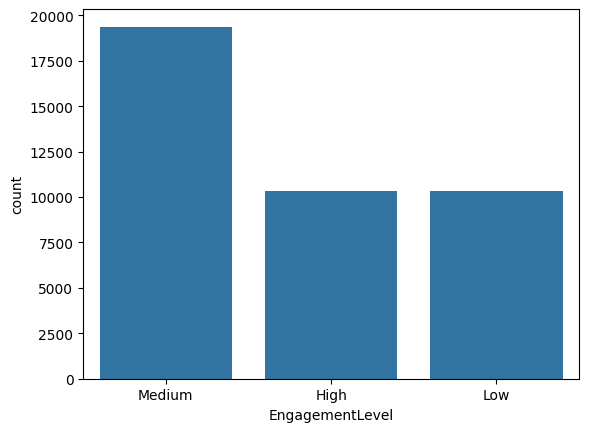

In [15]:
sns.countplot(data=df,x="EngagementLevel")

- Most players have a medium engagement level.high and low engagement players are almost same.

## 4.3 InGame purchases distribution

<Axes: xlabel='InGamePurchases', ylabel='count'>

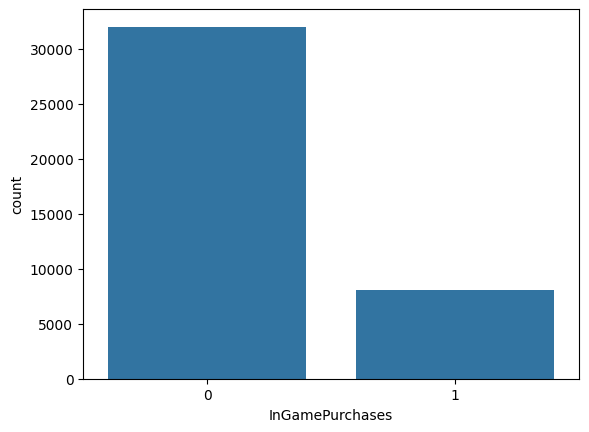

In [16]:
sns.countplot(data=df,x="InGamePurchases")

- Most of players didn't purchase a game,only a few player purchases a game.

## 4.4 Game difficulty distribution

<Axes: xlabel='GameDifficulty', ylabel='count'>

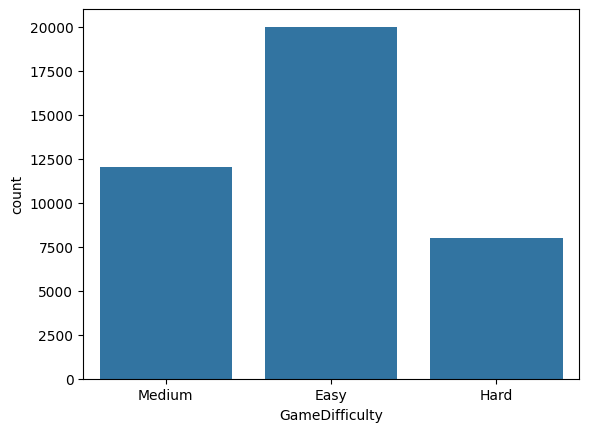

In [17]:
sns.countplot(data=df,x="GameDifficulty")

- Most of player selected a game which is easy in terms of difficulty.

## 4.5 Distribution of numerical features

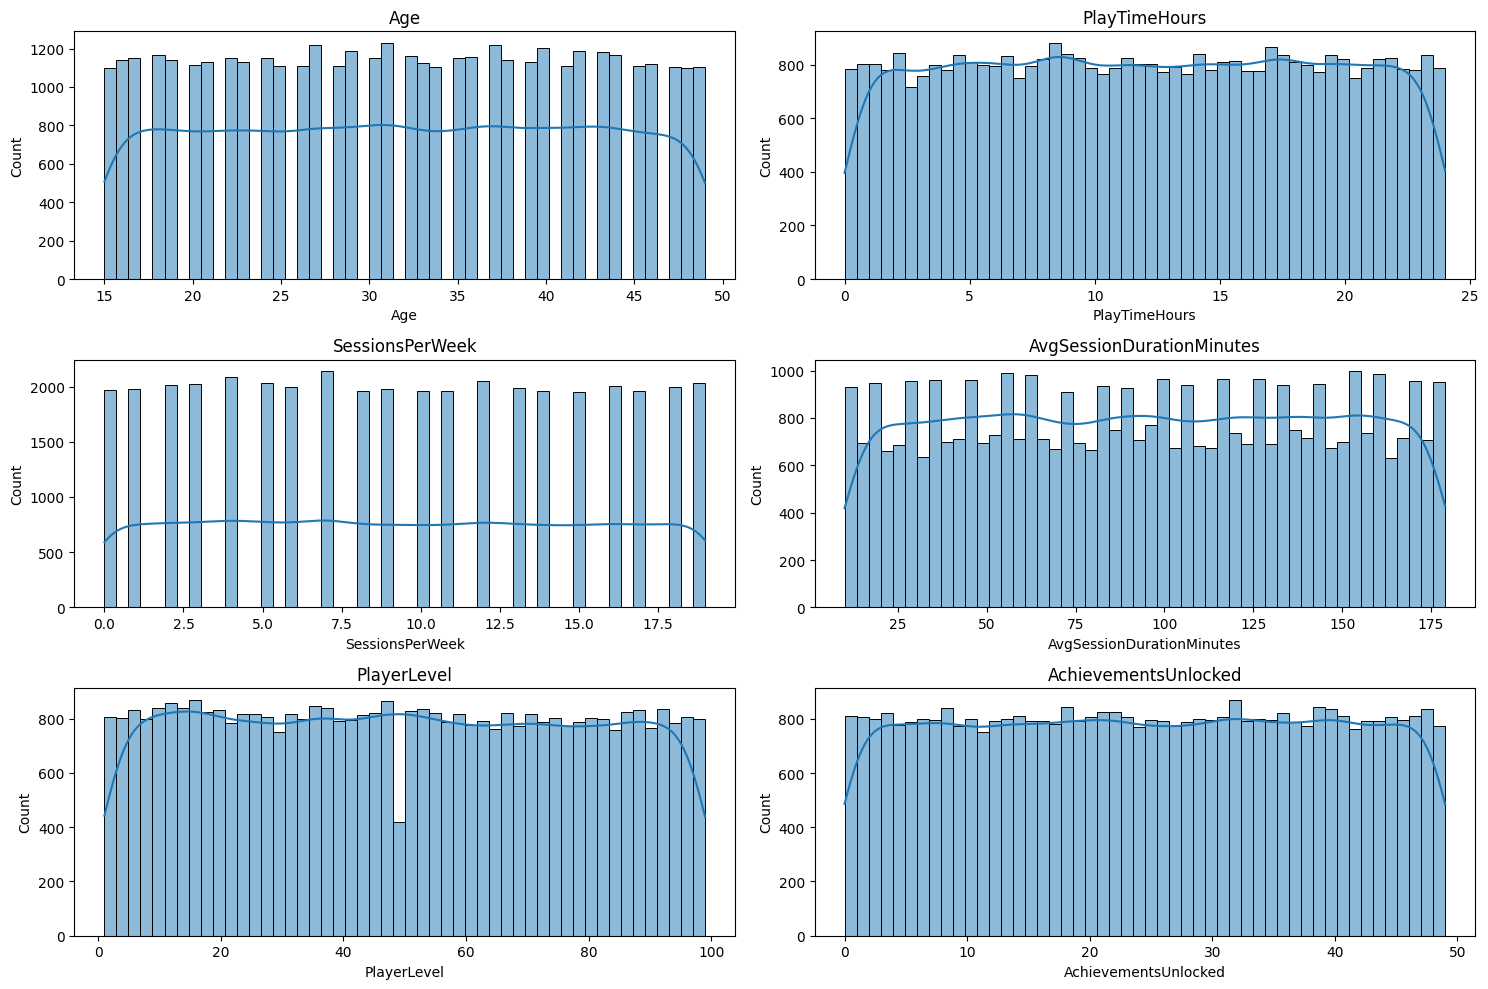

In [18]:
plt.figure(figsize=(15,10))
for i,col in enumerate(num_cols,1):
    plt.subplot(3,2,i)
    sns.histplot(df[col],bins=50,kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

- The numerical features are symmetric and evenly distributed with no any feature perfectly following a normal distribution.

## 4.6 Outlier analysis

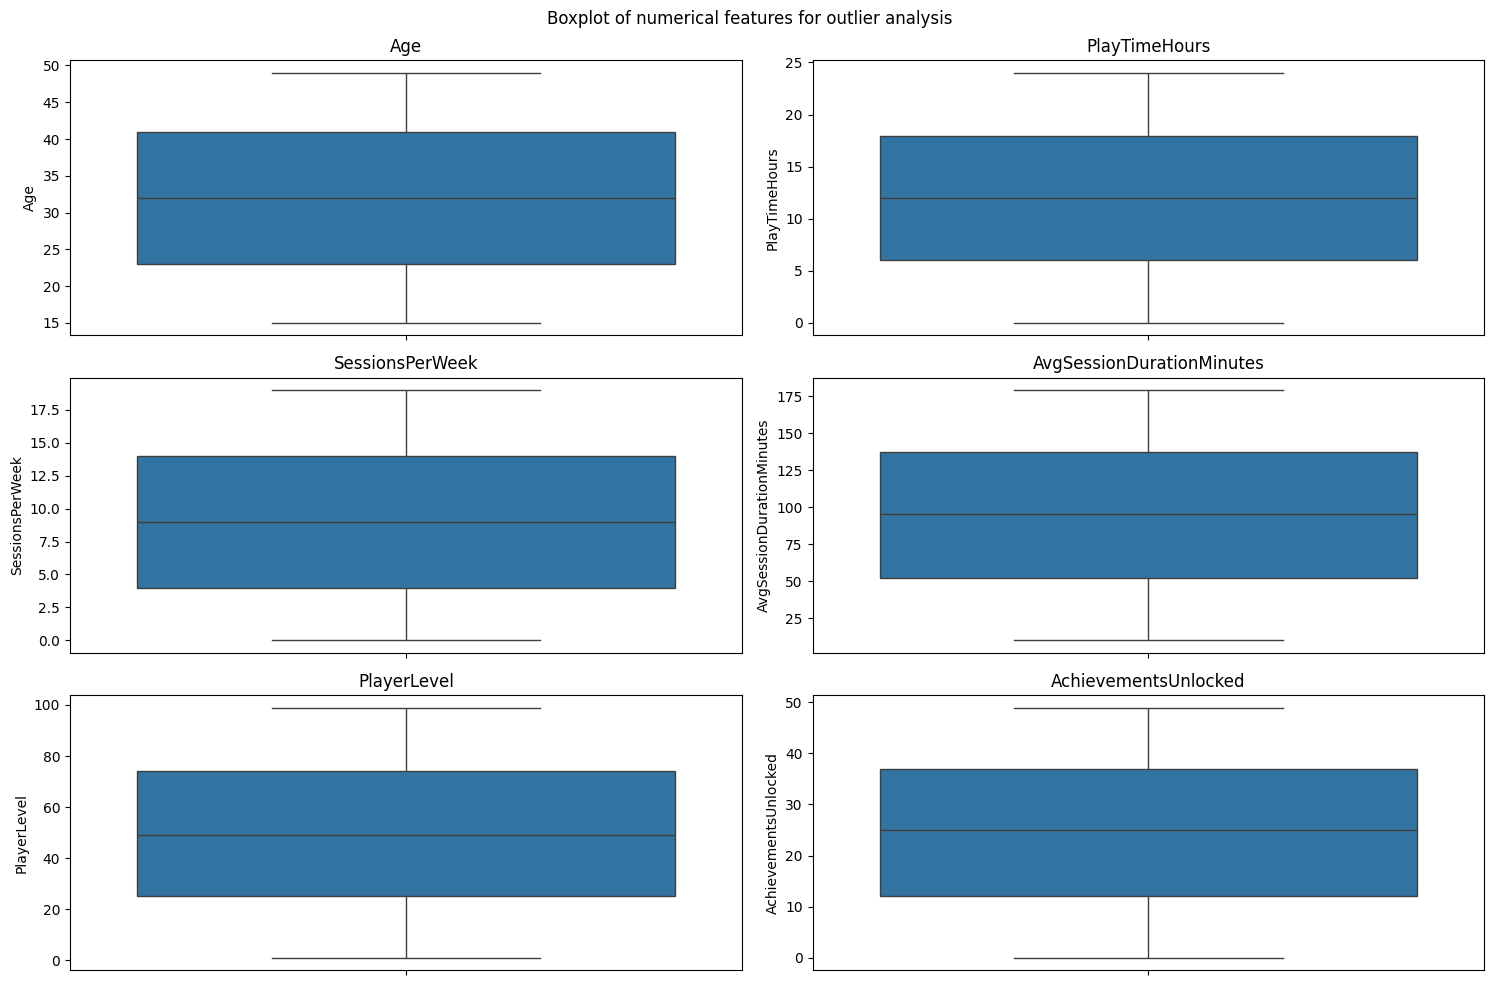

In [19]:
plt.figure(figsize=(15,10))
for i,col in enumerate(num_cols,1):
    plt.subplot(3,2,i)
    sns.boxplot(df[col])
    plt.title(col)
plt.suptitle("Boxplot of numerical features for outlier analysis")
plt.tight_layout()
plt.show()

- There is no outlier present in any columns,so outlier detection not require.

## 4.7 Categorical features across engagement level

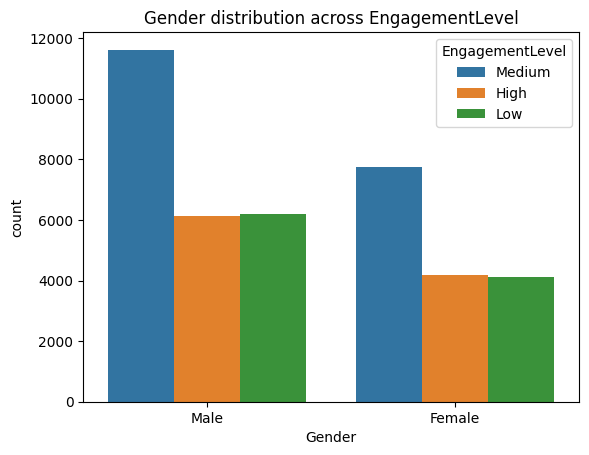

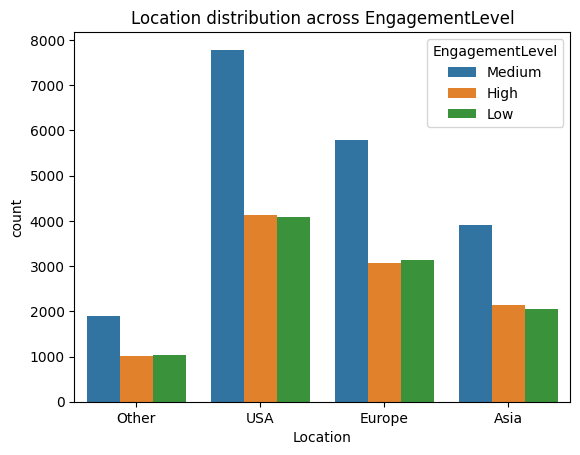

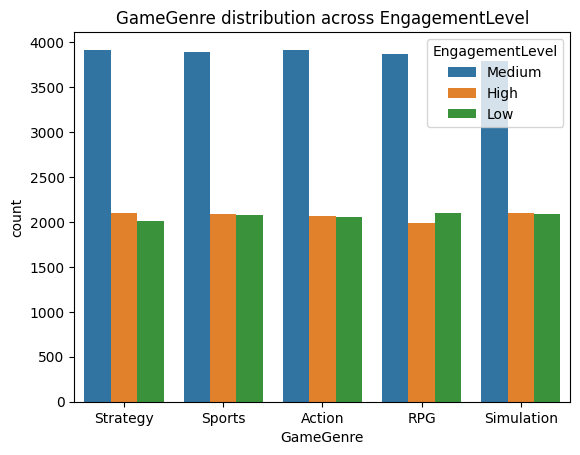

In [20]:
cols = ["Gender","Location","GameGenre"]
for i in cols:
    sns.countplot(data=df,x=df[i],hue="EngagementLevel")
    plt.title(f"{i} distribution across EngagementLevel")
    plt.show()

- Male and Female players similar engagement distribution.
- Engagement Levels are distributed similarly across all the locations and genre.

## 4.8 Game genre vs Game difficulty

<Axes: xlabel='GameGenre', ylabel='count'>

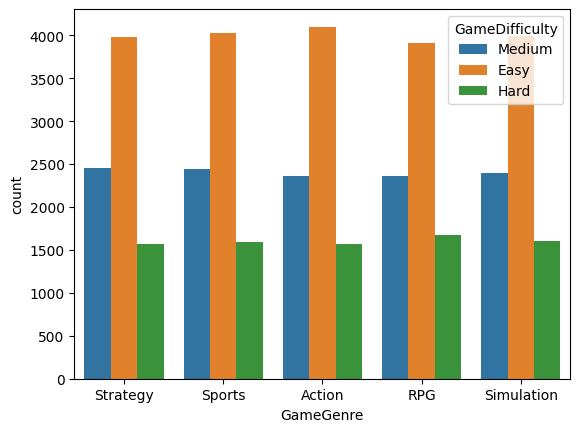

In [21]:
sns.countplot(data=df,x="GameGenre",hue="GameDifficulty")

In [22]:
pd.crosstab(df["GameGenre"],df["GameDifficulty"],normalize="index") * 100

GameDifficulty,Easy,Hard,Medium
GameGenre,,,
Action,51.001368,19.567110,29.431521
RPG,49.245473,21.038732,29.715795
Simulation,49.981210,20.067644,29.951146
Sports,50.000000,19.719185,30.280815
Strategy,49.737893,19.633050,30.629056


- Game difficulty vary by game genre.
- Most Action game players prefer the Easy difficulty level.

## 4.9 Numerical features distribution across Engagement level

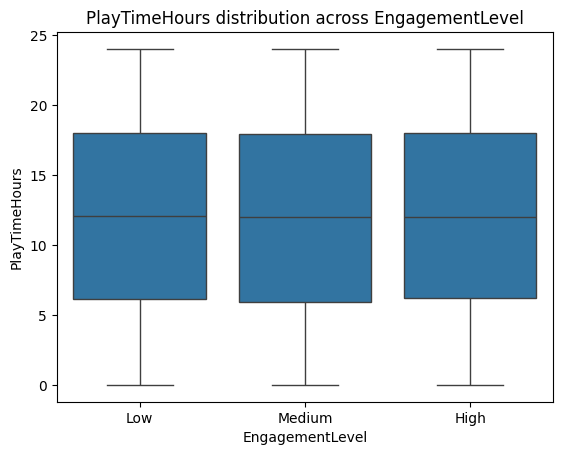

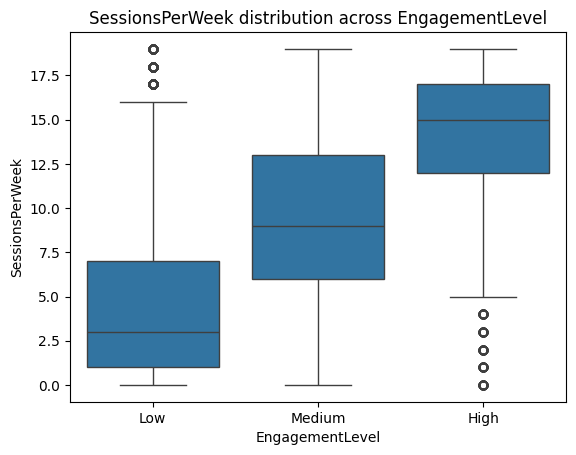

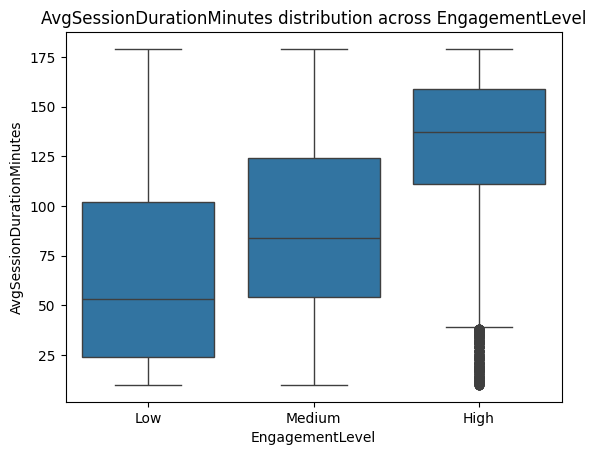

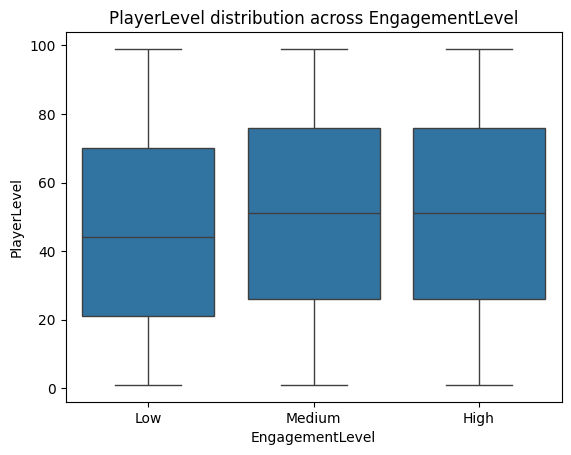

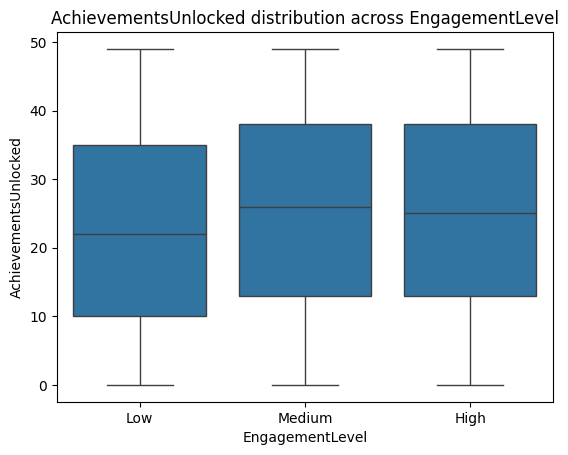

In [23]:
cols = ["PlayTimeHours","SessionsPerWeek","AvgSessionDurationMinutes","PlayerLevel","AchievementsUnlocked"]
for i in cols:
    sns.boxplot(x=df["EngagementLevel"],y=df[i],order=["Low","Medium","High"])
    plt.title(f"{i} distribution across EngagementLevel")
    plt.show()

- Highly engaged players play more session per week.
- They also have longer average session durations compare to other category.
- They reach higher player levels.
- They unlock more achievements.

## 4.10 Violin plot analysis

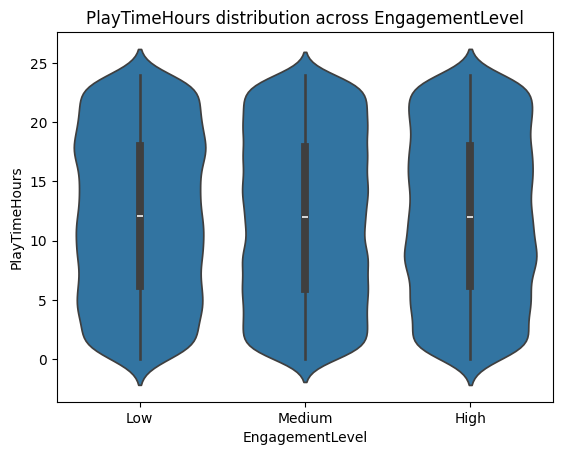

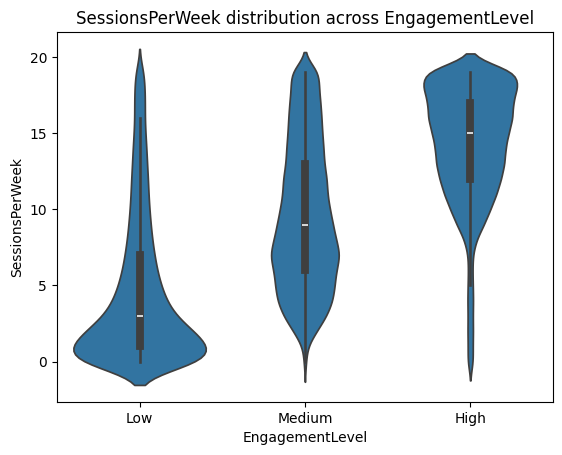

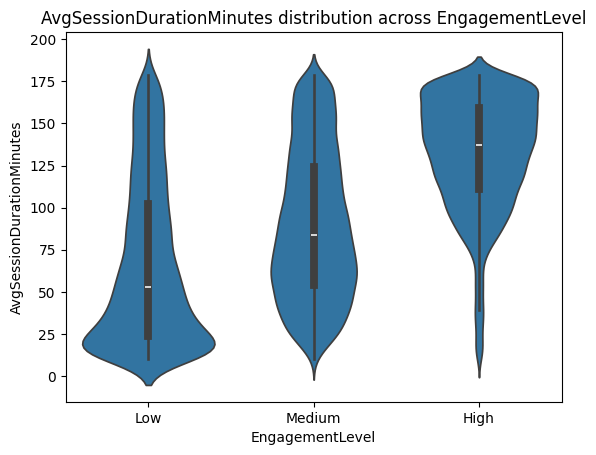

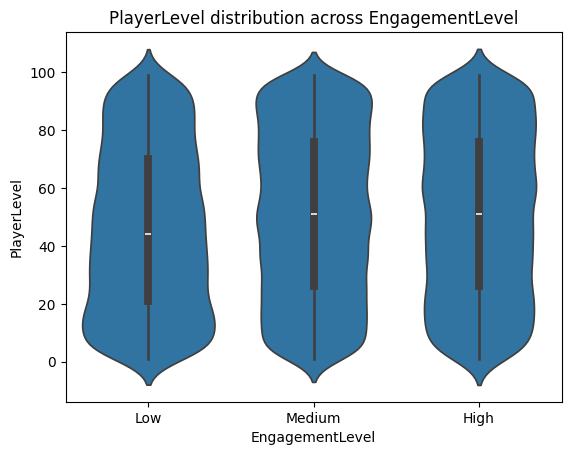

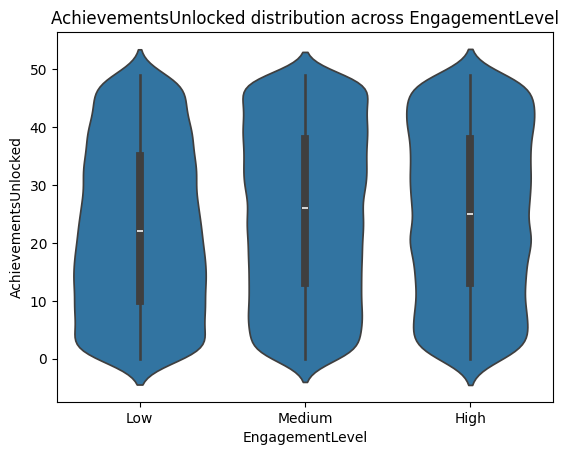

In [24]:
cols = ["PlayTimeHours","SessionsPerWeek","AvgSessionDurationMinutes","PlayerLevel","AchievementsUnlocked"]
for i in cols:
    sns.violinplot(x=df["EngagementLevel"],y=df[i],order=["Low","Medium","High"])
    plt.title(f"{i} distribution across EngagementLevel")
    plt.show()

- It indicate greater variability among highly engaged players.

## 4.11 Correlation heatmap

<Axes: >

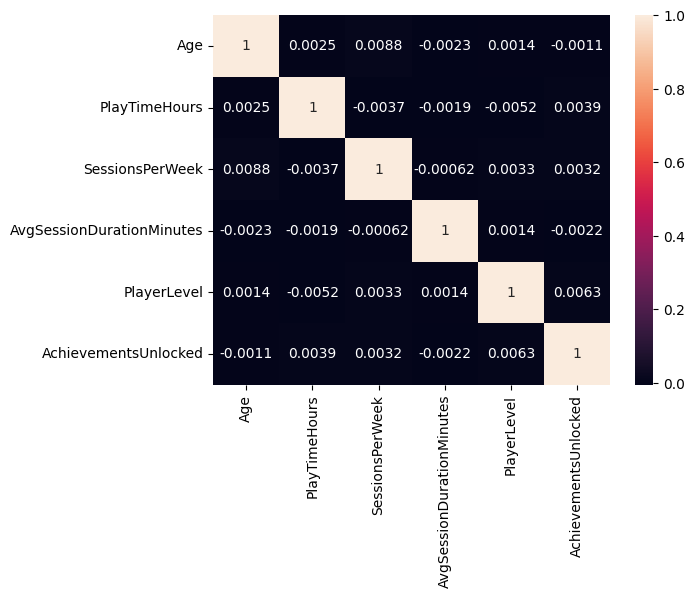

In [25]:
sns.heatmap(df[num_cols].corr(),annot=True)

- No extremely high correlation between any pair.

# 5.Data Preprocessing

In [26]:
df.head()

,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


## 5.1 Separate X and y

In [27]:
X = df.drop("EngagementLevel",axis=1)
y = df["EngagementLevel"]

## 5.2 Target feature encoding

In [28]:
mapping = {
    "Low":0,
    "Medium":1,
    "High":2
}
y = y.map(mapping) 

In [29]:
num_cols = X.select_dtypes(include=["int64","float64"]).columns
cat_GameDifficulty = ["GameDifficulty"]
cat_cols_other = X.select_dtypes(include=["object"]).columns.drop("GameDifficulty")

## 5.3 Train-test-split

In [30]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [31]:
# numerical feature pipeline
num_pipeline = Pipeline([
    ("scaler",StandardScaler())
])

In [32]:
# odinal encoding for GameDifficulty
cat_pipeline_GameDifficulty = Pipeline([
    ("oe",OrdinalEncoder(categories=[["Easy","Medium","Hard"]]))
])

In [33]:
# other categorical column pipeline
cat_other = Pipeline([
    ("ohe",OneHotEncoder(handle_unknown="ignore"))
])

In [34]:
preprocessor = ColumnTransformer([
    ("num",num_pipeline,num_cols),
    ("cat_gameDifficulty",cat_pipeline_GameDifficulty,cat_GameDifficulty),
    ("cat",cat_other,cat_cols_other)
],remainder="passthrough")

# 6.Model Building 

In [35]:
pipe = Pipeline([
    ("preprocessing",preprocessor),
    ("model",XGBClassifier(n_estimators=50,n_jobs=-1,random_state=42,eval_metric="logloss"))
])

In [36]:
pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)
accuracy_score(y_test,y_pred)

0.9133258398900962

In [37]:
cross_val_score(pipe,X,y,scoring="accuracy",cv=5).mean()

np.float64(0.916246061363806)

# 7.Classification Report

In [38]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.88      0.90      2093
           1       0.91      0.95      0.93      3879
           2       0.92      0.88      0.90      2035

    accuracy                           0.91      8007
   macro avg       0.91      0.90      0.91      8007
weighted avg       0.91      0.91      0.91      8007



# 8.Confusion Matrix

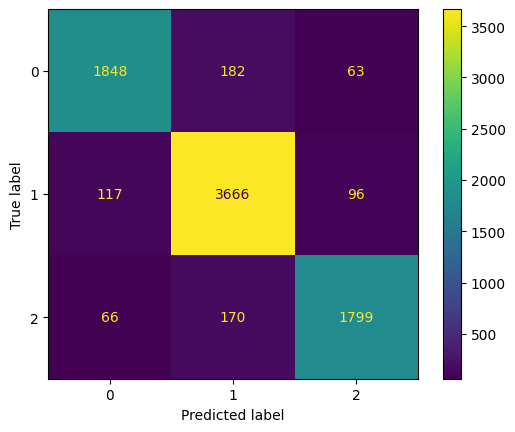

In [39]:
ConfusionMatrixDisplay.from_estimator(pipe,X_test,y_test)
plt.show()

# 8.Conclusion

- **XGBoost model achieved an accuracy and cross validation score 91%,It indicate a strong performance.**
- **Precision,Recall and F1-score are around 91% for every class.**
- **The macro average and weighted average 0.91,that indicate that model performs consistently across all classes.**

In [40]:
import joblib
joblib.dump(pipe,"online_gaming_behavior_model.pkl")

['online_gaming_behavior_model.pkl']